### Import Library dan Baca data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv('Superstore.csv', encoding='windows-1252')

In [7]:
print("Ukuran data:", df.shape)
display(df.head())
print(df.info())

Ukuran data: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

### Audit Kualitas Data

In [10]:
print("Nama Kolom:",df.columns.tolist())

Nama Kolom: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [11]:
print("Tipe Data:",df.dtypes)

Tipe Data: Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object


In [12]:
print("Missing Value:", df.isnull().sum())

Missing Value: Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [13]:
print("Duplikat:", df.duplicated().sum())

Duplikat: 0


In [14]:
print("Pesanan unik:", df["Order ID"].nunique())

Pesanan unik: 5009


In [15]:
display(df[["Sales", "Quantity", "Discount", "Profit"]].describe())

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


### Cleaning Data

In [21]:
# Salin data mentah agar tetap tersedia
clean = df.copy()

# Rapikan nama kolom dan teks
clean.columns = clean.columns.str.strip()

text_cols = clean.select_dtypes(include="object").columns

for col in text_cols:
    clean[col] = clean[col].str.strip()

# Konversi tanggal
for col in ["Order Date", "Ship Date"]:
    clean[col] = pd.to_datetime(
        clean[col],
        format="%m/%d/%Y",
        errors="coerce"
    )

# Konversi kolom numerik
numeric_cols = ["Sales", "Quantity", "Discount", "Profit"]

for col in numeric_cols:
    clean[col] = pd.to_numeric(
        clean[col],
        errors="coerce"
    )

# Periksa kembali setelah konversi
print("Missing values:")
print(clean.isnull().sum())

print("Duplikat identik:", clean.duplicated().sum())

print("Tanggal pemesanan:")
print(clean["Order Date"].min(), "sampai",
      clean["Order Date"].max())

Missing values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64
Duplikat identik: 0
Tanggal pemesanan:
2014-01-03 00:00:00 sampai 2017-12-30 00:00:00


C:\Users\faizi\AppData\Local\Temp\ipykernel_6348\2340620100.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = clean.select_dtypes(include="object").columns


### Validasi Data

In [22]:
# Tanggal pengiriman tidak seharusnya lebih awal
# daripada tanggal pemesanan
invalid_dates = clean[
    clean["Ship Date"] < clean["Order Date"]
]

# Nilai numerik yang hilang
missing_numeric = clean[numeric_cols].isnull().sum()

# Nilai quantity yang tidak positif
invalid_quantity = clean[clean["Quantity"] <= 0]

print("Tanggal tidak valid:", len(invalid_dates))
print("Quantity tidak valid:", len(invalid_quantity))
print("Missing numerik:\n", missing_numeric)

Tanggal tidak valid: 0
Quantity tidak valid: 0
Missing numerik:
 Sales       0
Quantity    0
Discount    0
Profit      0
dtype: int64


### Simpan Hasil Data Cleaning

In [23]:
clean.to_csv(
    "superstore_clean.csv",
    index=False
)

## Analisis A — KPI utama

In [24]:
total_sales = clean["Sales"].sum()
total_orders = clean["Order ID"].nunique()
total_quantity = clean["Quantity"].sum()
avarage_order_value = total_sales / total_orders

print("Total Penjualan:", total_sales)
print("Total Pesanan:", total_orders)
print("Total Kuantitas:", total_quantity)
print("Rata-rata Nilai Pesanan:", avarage_order_value)

Total Penjualan: 2297200.8603
Total Pesanan: 5009
Total Kuantitas: 37873
Rata-rata Nilai Pesanan: 458.6146656618087


## Analisis B — Tren penjualan bulanan

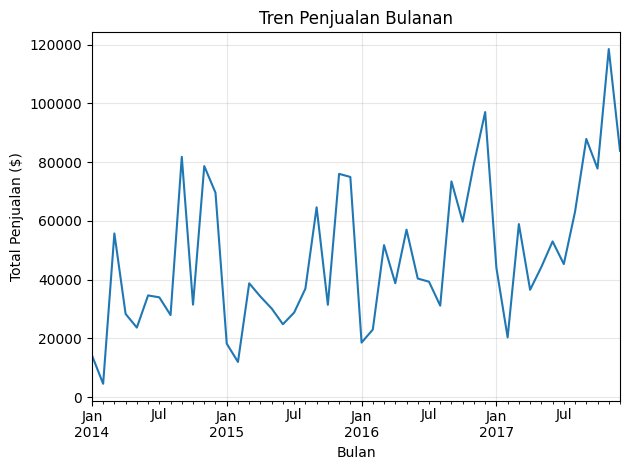

In [26]:
monthly_sales = (
    clean
    .set_index("Order Date")
    .resample("MS")["Sales"]
    .sum()
)

plt.Figure(figsize=(12, 6))
monthly_sales.plot()

plt.title("Tren Penjualan Bulanan")
plt.xlabel("Bulan")
plt.ylabel("Total Penjualan ($)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Analisis C - Pertumbuhan Penjualan Bulanan

In [27]:
monthly = monthly_sales.to_frame(name="Total Sales")

monthly["Previous Month Sales"] = monthly["Total Sales"].shift(1)

monthly["MoM Growth"] = (
    (monthly["Total Sales"] - monthly["Previous Month Sales"]) -1
) * 100

display(monthly.round(2))

,Total Sales,Previous Month Sales,MoM Growth
Order Date,,,
2014-01-01,14236.90,NaN,NaN
2014-02-01,4519.89,14236.90,-971800.30
2014-03-01,55691.01,4519.89,5117011.70
2014-04-01,28295.34,55691.01,-2739666.40
2014-05-01,23648.29,28295.34,-464805.80
2014-06-01,34595.13,23648.29,1094584.06
2014-07-01,33946.39,34595.13,-64973.46
2014-08-01,27909.47,33946.39,-603792.45
2014-09-01,81777.35,27909.47,5386688.23


## Analisis D - Performa Kategori Produk

In [30]:
category_sales = (
    clean.groupby("Category", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Orders=("Order ID", "nunique")
    )
    .sort_values(by="Total_Sales", ascending=False)
)

display(category_sales)

,Category,Total_Sales,Total_Quantity,Orders
2,Technology,836154.0330,6939,1544
0,Furniture,741999.7953,8028,1764
1,Office Supplies,719047.0320,22906,3742


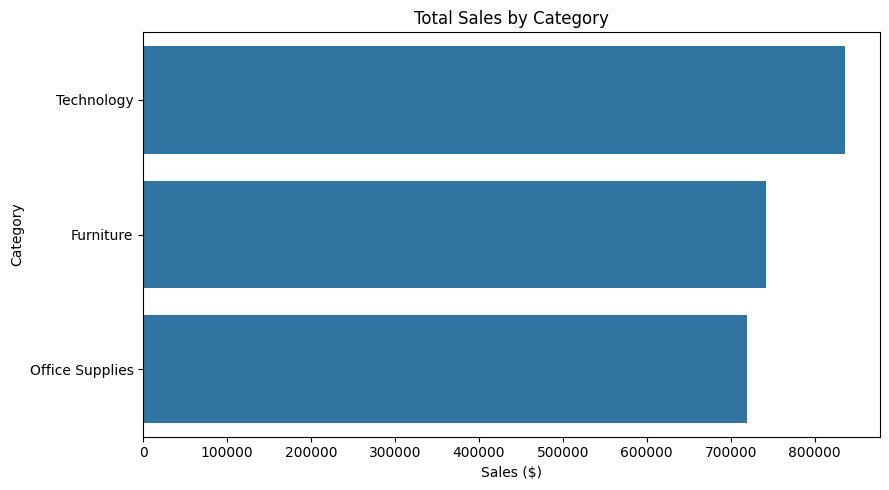

In [31]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_sales,
    x="Total_Sales",
    y="Category"
)

plt.title("Total Sales by Category")
plt.xlabel("Sales ($)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

## Analisis E — Performa wilayah

In [32]:
region_sales = (
    clean.groupby("Region", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Orders=("Order ID", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(region_sales)

,Region,Total_Sales,Total_Quantity,Orders
3,West,725457.8245,12266,1611
1,East,678781.2400,10618,1401
0,Central,501239.8908,8780,1175
2,South,391721.9050,6209,822


## Analisis F — Cari bulan terbaik dan terendah

In [33]:
monthly_table = (
    clean.assign(
        Month=clean["Order Date"].dt.to_period("M").astype(str)
    )
    .groupby("Month", as_index=False)
    .agg(Total_Sales=("Sales", "sum"))
)

best_month = monthly_table.loc[
    monthly_table["Total_Sales"].idxmax()
]

worst_month = monthly_table.loc[
    monthly_table["Total_Sales"].idxmin()
]

print("Bulan penjualan tertinggi:")
print(best_month)

print("\nBulan penjualan terendah:")
print(worst_month)

Bulan penjualan tertinggi:
Month             2017-11
Total_Sales    118447.825
Name: 46, dtype: object

Bulan penjualan terendah:
Month           2014-02
Total_Sales    4519.892
Name: 1, dtype: object
